# 03 · Business Findings
*From metrics to decisions: what happened, what drove it, where to act.*

> ⚠️ **Synthetic data.** These notebooks run on the generated M5-shaped sample so every
> cell is reproducible out of the box. The *mechanics* are real; the *numbers are not a
> business finding*. Set `data_source.mode: real` in `config.yaml`, drop the Kaggle M5
> files into `data/raw/`, run `make all`, and re-run — every cell applies unchanged.

In [1]:
import os
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')  # run from project root whether launched here or above
import duckdb, pandas as pd, numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.figsize': (9, 4), 'axes.grid': True, 'grid.alpha': .3, 'axes.spines.top': False, 'axes.spines.right': False})
con = duckdb.connect('data/processed/rci.duckdb', read_only=True)
EXT = 'dashboard/extracts'
pd.set_option('display.width', 150); pd.set_option('display.max_columns', 20)

## The headline (current period vs. same period last year)

In [2]:
import json
summary = json.load(open(f'{EXT}/metrics_summary.json'))
print('window:', summary['current_window'], 'vs', summary['prior_window'])
display(pd.read_csv(f'{EXT}/kpi_summary.csv'))

window: ['2014-10-03', '2014-12-31'] vs ['2013-10-03', '2013-12-31']


,metric,current,prior,growth
0,Estimated Sales Value,2.192579e+06,2.125470e+06,0.0316
1,Units Sold,4.208070e+05,4.141680e+05,0.0160
2,Avg Selling Price,5.210400e+00,5.131900e+00,0.0153
3,At-Risk Value (deteriorating segments),1.099141e+05,NaN,NaN


## 1 · What drove the change — contribution by category
Contribution decomposes the top-line move: a small category can dominate the *change*.

,cat_id,value_cur,value_delta,demand_growth,share_of_change
0,HOUSEHOLD,914329.89,57528.78,0.063,0.857
1,FOODS,992466.10,16533.45,0.011,0.246
2,HOBBIES,285783.12,-6953.23,-0.025,-0.104


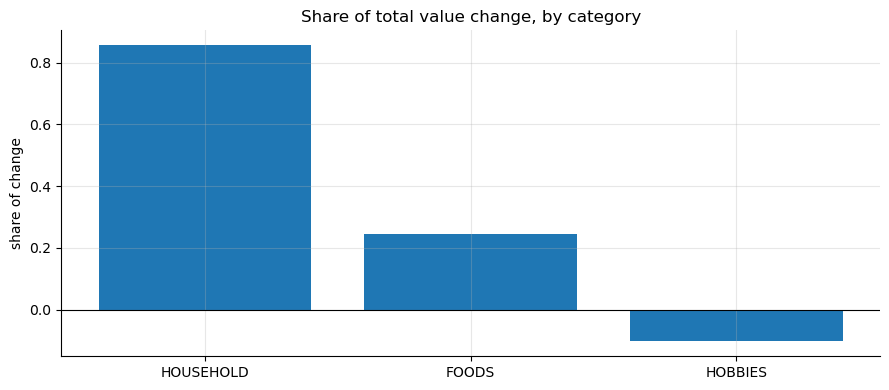

In [3]:
c = pd.read_csv(f'{EXT}/contribution_category.csv')
display(c[['cat_id','value_cur','value_delta','demand_growth','share_of_change']].round(3))
plt.bar(c.cat_id, c.share_of_change); plt.axhline(0, color='k', lw=.8)
plt.title('Share of total value change, by category'); plt.ylabel('share of change'); plt.tight_layout(); plt.show()

## 2 · Where to look — the exception table
Store×category segments the engine flagged, ranked by priority score
(Impact × Magnitude × Confidence).

In [4]:
exc = pd.read_csv(f'{EXT}/exceptions_store_category.csv')
display(exc)

,priority,store_key,state_id,cat_id,signal,demand_growth,price_change,contribution_share,value_delta,priority_score
0,High,CA_3,CA,HOUSEHOLD,Strong growth,0.3487,-0.0068,0.0664,36925.48,2.3
1,High,CA_1,CA,FOODS,Strong growth,0.2038,0.0115,0.0839,32876.21,1.7
2,Medium,CA_1,CA,HOUSEHOLD,Demand deterioration,-0.2207,0.0037,0.0306,-18696.48,0.7
3,Low,WI_1,WI,HOBBIES,Demand deterioration,-0.1971,0.0034,0.0120,-6355.09,0.2
4,Low,CA_2,CA,HOBBIES,Demand deterioration,-0.2460,0.0070,0.0075,-5214.37,0.1


## 3 · Risks — price-risk items & concentration

In [5]:
risk = pd.read_csv(f'{EXT}/price_risk_items.csv')
print('Price ↑ / demand ↓ (top items):'); display(risk.head(8))
print('\nConcentration:'); display(pd.read_csv(f'{EXT}/concentration.csv'))

Price ↑ / demand ↓ (top items):


,store_key,product_key,dept_id,cat_id,price_change,demand_growth,value_delta,units_prior
0,WI_2,HOUSEHOLD_2_001,HOUSEHOLD_2,HOUSEHOLD,0.0922,-0.4100,-879.00,200.0
1,TX_2,HOUSEHOLD_2_001,HOUSEHOLD_2,HOUSEHOLD,0.0821,-0.5397,-754.40,126.0
2,WI_2,FOODS_3_030,FOODS_3,FOODS,0.0618,-0.3660,-492.63,582.0
3,CA_3,FOODS_1_004,FOODS_1,FOODS,0.0681,-0.3303,-386.40,545.0
4,CA_1,HOUSEHOLD_1_023,HOUSEHOLD_1,HOUSEHOLD,0.0854,-0.2513,-368.56,191.0
5,CA_1,HOUSEHOLD_2_023,HOUSEHOLD_2,HOUSEHOLD,0.1404,-0.4457,-313.36,92.0
6,WI_1,HOUSEHOLD_2_028,HOUSEHOLD_2,HOUSEHOLD,0.0831,-0.1732,-287.61,179.0
7,TX_3,HOUSEHOLD_2_007,HOUSEHOLD_2,HOUSEHOLD,0.0677,-0.2381,-280.65,105.0



Concentration:


,dimension,universe,top_k,top_k_share,hhi
0,products,210,10,0.1556,0.0075
1,stores,10,3,0.4059,0.1088


## 4 · Implications (what management should investigate)
*Written against synthetic data as a template; rewrite from the real run.*

1. **Protect the growth engine.** The category driving most of the positive change is
   concentrated in a few stores — confirm supply and shelf space there before anything else.
2. **Investigate the deteriorating segments** at the top of the exception table first; they
   pair a large business share with a double-digit demand decline.
3. **Review the price-risk list.** These items raised price and lost volume — a margin-vs-
   volume decision the pricing team should make deliberately, not by drift.
4. **Watch concentration.** Track the top-k share and HHI over time so dependence on a few
   products/stores is a monitored risk, not a surprise.